# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3388 Шубин Павел Александрович. Вариант №21.


## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.


## Основные теоретические положения

Линейная стационарная дискретная система с нулевыми начальными условиями описывается передаточной функцией

$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{a_0+a_1z^{-1}+a_2z^{-2}}.$$

При $a_0=1$ ей соответствует разностное уравнение

$$y[n]=\sum_{i=0}^{2}b_i x[n-i]-a_1y[n-1]-a_2y[n-2].$$

Для причинной системы $h[n]=0$ при $n<0$. Импульсная характеристика $h[n]$ — реакция на единичный импульс $\delta[n]$. Реакция на произвольное воздействие определяется свёрткой:

$$y[n]=\sum_{m=-\infty}^{\infty}x[m]h[n-m].$$

Линейная свёртка массивов длины $L_x$ и $L_h$ содержит $L_x+L_h-1$ отсчётов. Это длина вычисленного массива, а не обязательно число ненулевых отсчётов. Причинная рациональная система устойчива, если все её полюсы лежат строго внутри единичной окружности.

Частотная характеристика получается подстановкой $z=e^{j\widehat\omega}$:

$$H(e^{j\widehat\omega})=|H(e^{j\widehat\omega})|e^{j\varphi(\widehat\omega)},\qquad \widehat\omega=\frac{2\pi f}{f_s}.$$

Она периодична с периодом $2\pi$. Основную полосу можно выбрать как $[-\pi,\pi)$; для вещественных коэффициентов достаточно изобразить $[0,\pi]$.

Для $N$ отсчётов используется следующая пара ДПФ и ОДПФ:

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

Коэффициенты комплексного ряда Фурье периодической последовательности равны $C[k]=X[k]/N$. В работе амплитудный спектр периодической последовательности понимается как двусторонний спектр $|C[k]|$: каждой из двух линий косинуса амплитуды $A$ соответствует величина $A/2$. Фаза определена только у ненулевых коэффициентов.

Обозначения времени и частоты:

$$t_n=nT,\quad T=1/f_s,\quad \nu_k=k/N,\quad \widehat\omega_k=2\pi\nu_k,\quad f_k=\nu_k f_s.$$

Здесь $n$ — дискретное нормированное время (номер отсчёта), $t_n=nT$ — дискретное физическое время в секундах, $\nu$ — нормированная частота в циклах на отсчёт. Для индексов $k>N/2$ физическим отрицательным частотам соответствуют индексы $k-N$.

Равенство Парсеваля при принятой нормировке имеет вид

$$\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2.$$

Оно выражает равенство энергии конечной последовательности, вычисленной во временной и частотной областях. Для бесконечной периодической последовательности конечной величиной является средняя мощность, то есть энергия одного периода, делённая на $N$.


## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

В первой части требуется вычислить импульсную характеристику, реакции по свёртке и разностному уравнению, нули и полюсы, АЧХ и ФЧХ. Во второй части требуется исследовать сумму двух гармоник с помощью ДПФ и ОДПФ, сопоставить спектры конечной и периодической последовательностей, восстановить аналоговый сигнал и проверить равенство Парсеваля.

### Исходные данные варианта 21

Для первой части при $V=21$:

| Параметр | Формула задания | Значение |
|---|---|---|
| $b_0$ | $0.5+0.02V$ | $0.92$ |
| $b_1$ | $b_0(-1)^{V+1}(0.9822+0.0178V)$ | $1.24752$ |
| $b_2$ | $b_0(0.8+0.2(V\bmod 5))$ | $0.92$ |
| $a_0$ | $1$ | $1$ |
| $a_1$ | $(-1)^V(0.7778+0.025V)$ | $-1.3028$ |
| $a_2$ | $0.64+0.006V$ | $0.766$ |
| $N_1$ | $V\bmod 10+20$ | $21$ |
| $N_2$ | $V\bmod 10+30$ | $31$ |
| $f_{s,1}$ | $1000V$ | $21000$ Гц |

Для второй части:

| Параметр | Формула задания | Значение |
|---|---|---|
| $N$ | $64$ | $64$ |
| $f_{s,2}$ | $2000(V\bmod 5+1)$ | $4000$ Гц |
| $T$ | $1/f_{s,2}$ | $0.00025$ с |
| $A_1$ | $1+0.01V$ | $1.21$ |
| $A_2$ | $2A_1$ | $2.42$ |
| $f_1$ | $f_{s,2}/8$ | $500$ Гц |
| $f_2$ | $1.5f_1$ | $750$ Гц |

Источники условия: [практическая работа №1](https://se.moevm.pro/doku.php/courses:digital_signal_processing:prac1), [таблица вариантов](https://se.moevm.pro/doku.php/courses:digital_signal_processing:prac1:prac1-vars). Структура отчёта соответствует предоставленному шаблону `task0.ipynb`.


## Выполнение работы

### Подготовка


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

np.set_printoptions(precision=8, suppress=True)
plt.rcParams.update({"figure.figsize": (10, 3.5), "font.size": 11})

variant = 21
b0 = 0.5 + 0.02 * variant
b = np.array([
    b0,
    b0 * (-1)**(variant + 1) * (0.9822 + 0.0178 * variant),
    b0 * (0.8 + 0.2 * (variant % 5)),
])
a = np.array([1.0, (-1)**variant * (0.7778 + 0.025 * variant),
              0.64 + 0.006 * variant])
N1 = variant % 10 + 20
N2 = variant % 10 + 30
fs1 = 1000 * variant

print("b =", b)
print("a =", a)
print(f"N1 = {N1}; N2 = {N2}; fs1 = {fs1} Гц")


b = [0.92    1.24752 0.92   ]
a = [ 1.     -1.3028  0.766 ]
N1 = 21; N2 = 31; fs1 = 21000 Гц


### Часть 1. Линейная дискретная система

#### 1. Импульсная характеристика

Передаточная функция заданного звена:

$$H(z)=\frac{0.92+1.24752z^{-1}+0.92z^{-2}}{1-1.3028z^{-1}+0.766z^{-2}}.$$

Обозначим полюсы знаменателя через $p_{1,2}=re^{\pm j\phi}$, где

$$r=\sqrt{0.766},\qquad \phi=\arccos\frac{1.3028}{2r}.$$

Так как $1-1.3028z^{-1}+0.766z^{-2}=(1-p_1z^{-1})(1-p_2z^{-1})$, обратное $z$-преобразование единицы, делённой на знаменатель, равно

$$g[n]=\frac{p_1^{n+1}-p_2^{n+1}}{p_1-p_2}=r^n\frac{\sin((n+1)\phi)}{\sin\phi},\quad n\geq0;\qquad g[n]=0,\quad n<0.$$

Отсюда аналитическая импульсная характеристика с нулевыми начальными условиями:

$$\boxed{h[n]=0.92g[n]+1.24752g[n-1]+0.92g[n-2].}$$

Фрагмент из $N_1=21$ отсчёта вычисляется фильтрацией единичного импульса. Результат сопоставляется с аналитической формулой.


r = 0.87521426; phi/pi = 0.23279525
Первые четыре отсчёта h: [0.92       2.446096   3.40205387 2.55848624]
Ошибка аналитической формулы: 8.882e-16


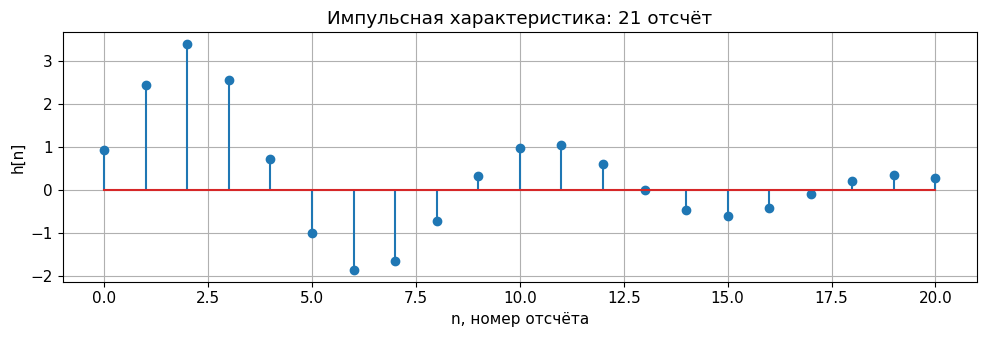

In [2]:
n_h = np.arange(N1)
delta = np.zeros(N1)
delta[0] = 1
h = signal.lfilter(b, a, delta)

r = np.sqrt(a[2])
phi = np.arccos(-a[1] / (2 * r))

def g(n):
    n = np.asarray(n)
    return np.where(n >= 0, r**n * np.sin((n + 1) * phi) / np.sin(phi), 0.0)

h_formula = sum(b[i] * g(n_h - i) for i in range(3))
error_h = np.max(np.abs(h - h_formula))
assert np.allclose(h, h_formula, atol=1e-12, rtol=0)
print(f"r = {r:.8f}; phi/pi = {phi / np.pi:.8f}")
print("Первые четыре отсчёта h:", h[:4])
print(f"Ошибка аналитической формулы: {error_h:.3e}")

plt.figure()
plt.stem(n_h, h)
plt.xlabel("n, номер отсчёта")
plt.ylabel("h[n]")
plt.title("Импульсная характеристика: 21 отсчёт")
plt.grid()
plt.tight_layout()
plt.show()


При $r\approx0.87521426<1$ колебания затухают, но не обрываются после $n=20$. Настоящая импульсная характеристика бесконечна: полюсы ненулевые и не сокращаются с нулями числителя. Число $N_1=21$ задаёт длину вычисленного фрагмента. Например, следующий отсчёт $h[21]\approx0.10986495$ ещё отличен от нуля.


#### 2. Реакция по формуле свёртки

В условии $\operatorname{int}$ означает округление до ближайшего целого. Для положительной половины используется округление вверх: $M=\lfloor N_2/2+0.5\rfloor=16$. Таким образом,

$$x[n]=\begin{cases}1,&0\leq n<16,\\0,&16\leq n\leq30.\end{cases}$$

Длина массива воздействия равна $N_2=31$, длительность ненулевого прямоугольного импульса — $16$ отсчётов. Вычисляется линейная свёртка $y_1[n]=(x*h_{21})[n]$, где $h_{21}$ — усечённая импульсная характеристика.


Длина массива x: 31; ненулевых отсчётов: 16
Длина полной свёртки: 21 + 31 - 1 = 51
Последний ненулевой отсчёт свёртки: n = 35


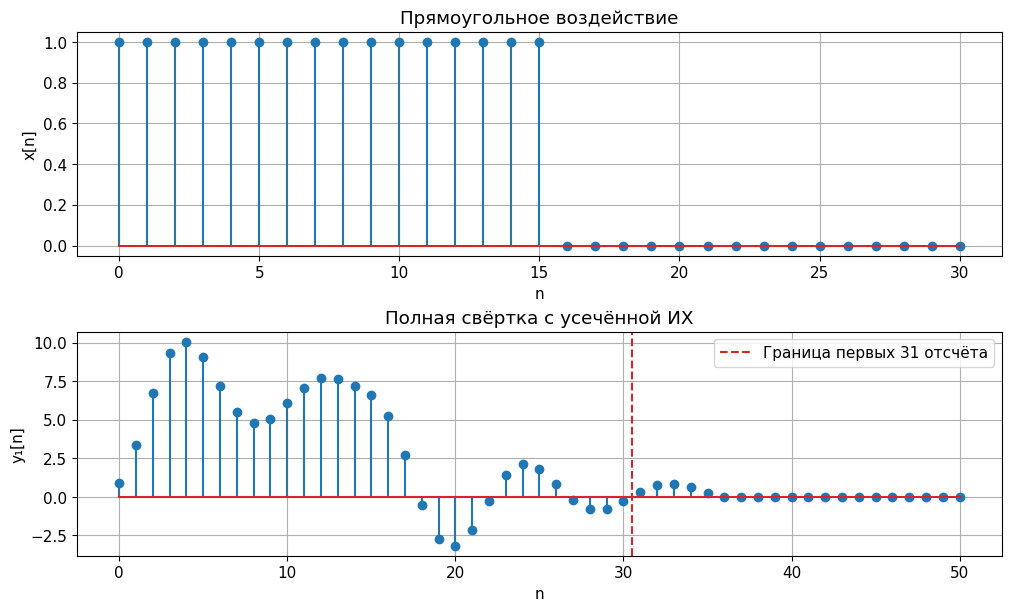

In [3]:
n_x = np.arange(N2)
pulse_length = int(np.floor(N2 / 2 + 0.5))
x1 = (n_x < pulse_length).astype(float)
y1_full = np.convolve(x1, h, mode="full")
y1 = y1_full[:N2]
nonzero = np.flatnonzero(np.abs(y1_full) > 1e-12)
print(f"Длина массива x: {len(x1)}; ненулевых отсчётов: {pulse_length}")
print(f"Длина полной свёртки: {N1} + {N2} - 1 = {len(y1_full)}")
print(f"Последний ненулевой отсчёт свёртки: n = {nonzero[-1]}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(n_x, x1)
axes[0].set(xlabel="n", ylabel="x[n]", title="Прямоугольное воздействие")
axes[1].stem(np.arange(len(y1_full)), y1_full)
axes[1].axvline(N2 - 0.5, color="tab:red", ls="--", label="Граница первых 31 отсчёта")
axes[1].set(xlabel="n", ylabel="y₁[n]", title="Полная свёртка с усечённой ИХ")
axes[1].legend()
for ax in axes:
    ax.grid()
plt.show()


Аналитическая длина свёртки двух заданных массивов равна $21+31-1=51$: на графике представлены индексы $0,\ldots,50$. Ненулевая часть занимает $21+16-1=36$ отсчётов, то есть $n=0,\ldots,35$, затем следуют 15 нулей из-за нулевого окончания массива воздействия.

Ограничение до первых $N_2=31$ отсчёта задаёт одинаковый интервал наблюдения для сравнения с разностным уравнением. Оно не означает, что реакция системы заканчивается в этот момент. Более того, свёртка с полной, бесконечной ИХ имеет бесконечный затухающий хвост.


#### 3. Реакция по разностному уравнению

Для заданных коэффициентов:

$$\boxed{y_2[n]=1.3028y_2[n-1]-0.766y_2[n-2]+0.92x[n]+1.24752x[n-1]+0.92x[n-2].}$$

При $n<0$ значения входа и выхода равны нулю. Уравнение реализуется непосредственно, а `lfilter` используется для проверки.


Ошибка сравнения до n = 20: 3.553e-15
Максимальное расхождение на 31 отсчёте: 0.42225839
Первое расхождение y2[21] - y1[21]: 0.10986495


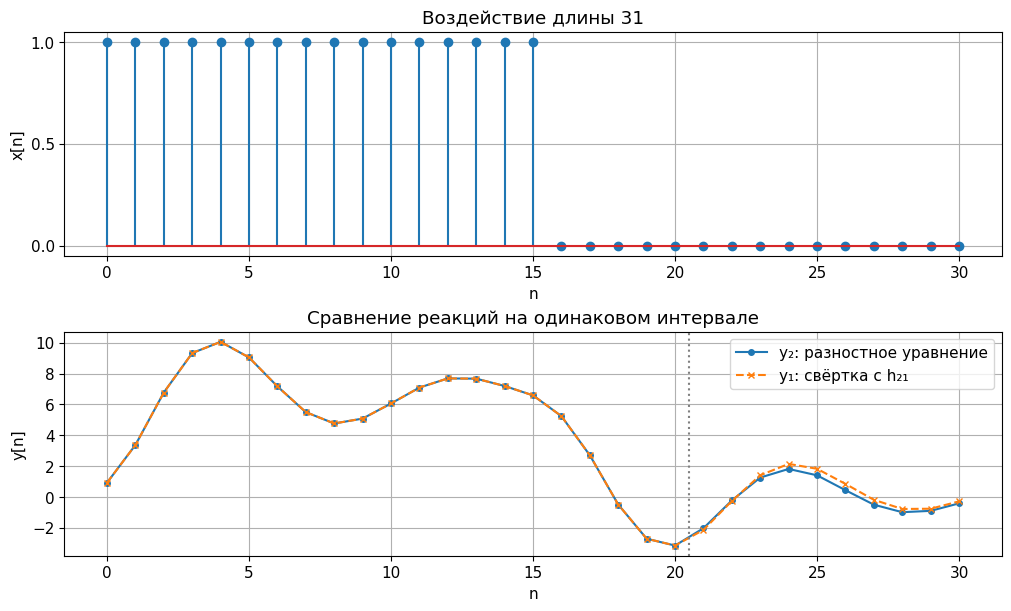

In [4]:
y2 = np.zeros(N2)
for n in range(N2):
    for i in range(3):
        if n >= i:
            y2[n] += b[i] * x1[n - i]
    for i in range(1, 3):
        if n >= i:
            y2[n] -= a[i] * y2[n - i]

assert np.allclose(y2, signal.lfilter(b, a, x1), atol=1e-12, rtol=0)
error_before_cut = np.max(np.abs(y1[:N1] - y2[:N1]))
error_response = np.max(np.abs(y1 - y2))
assert error_before_cut < 1e-12
print(f"Ошибка сравнения до n = {N1 - 1}: {error_before_cut:.3e}")
print(f"Максимальное расхождение на 31 отсчёте: {error_response:.8f}")
print(f"Первое расхождение y2[21] - y1[21]: {y2[21] - y1[21]:.8f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(n_x, x1)
axes[0].set(xlabel="n", ylabel="x[n]", title="Воздействие длины 31")
axes[0].set_yticks([0, 0.5, 1])
axes[1].plot(n_x, y2, "o-", label="y₂: разностное уравнение", markersize=4)
axes[1].plot(n_x, y1, "x--", label="y₁: свёртка с h₂₁", markersize=5)
axes[1].axvline(N1 - 0.5, color="gray", ls=":")
axes[1].set(xlabel="n", ylabel="y[n]", title="Сравнение реакций на одинаковом интервале")
axes[1].set_yticks(np.arange(-2, 11, 2))
axes[1].legend()
for ax in axes:
    ax.grid()
plt.show()


На интервале $0\leq n<21$ реакции совпадают с точностью вычислений. Начиная с $n=21$ свёртке недостаёт отброшенного хвоста $h[n]$, поэтому максимальное расхождение на выбранном интервале составляет примерно $0.42225839$. Первое расхождение равно $h[21]x[0]\approx0.10986495$. Это следствие усечения ИХ, а не различие между двумя точными способами описания системы.

Массивы входа и вычисленного выхода содержат по 31 отсчёту. При продолжении вычисления с нулевым входом после $n=30$ разностное уравнение даст бесконечный затухающий хвост. Чтобы получить точное совпадение на всех первых 31 отсчёте, для свёртки достаточно вычислить первые 31 отсчёт ИХ.


#### 4. Нули и полюсы

После умножения числителя и знаменателя на $z^2$ нули являются корнями $0.92z^2+1.24752z+0.92$, а полюсы — корнями $z^2-1.3028z+0.766$. Переход между формами комплексного числа:

$$z=x+jy=\rho e^{j\theta},\qquad \rho=\sqrt{x^2+y^2},\quad \theta=\operatorname{atan2}(y,x).$$


In [5]:
zeros = np.roots(b)
poles = np.roots(a)
z_check, p_check, gain = signal.tf2zpk(b, a)
assert np.allclose(np.sort_complex(zeros), np.sort_complex(z_check))
assert np.allclose(np.sort_complex(poles), np.sort_complex(p_check))

print("Корень       Алгебраическая форма         Модуль       arg/pi")
for name, roots in [("z", zeros), ("p", poles)]:
    for i, root in enumerate(roots, 1):
        print(f"{name}{i}       {root.real:.8f}{root.imag:+.8f}j"
              f"     {abs(root):.8f}    {np.angle(root) / np.pi:+.8f}")
print(f"Множитель: {gain:.8f}")


Корень       Алгебраическая форма         Модуль       arg/pi
z1       -0.67800000+0.73506190j     1.00000000    +0.73715307
z2       -0.67800000-0.73506190j     1.00000000    -0.73715307
p1       0.65140000+0.58453233j     0.87521426    +0.23279525
p2       0.65140000-0.58453233j     0.87521426    -0.23279525
Множитель: 0.92000000


| Корни | Алгебраическая форма | Показательная форма |
|---|---|---|
| Нули $z_{1,2}$ | $-0.678\pm j0.73506190$ | $e^{\pm j0.73715307\pi}$ |
| Полюсы $p_{1,2}$ | $0.6514\pm j0.58453233$ | $0.87521426e^{\pm j0.23279525\pi}$ |

Обе пары комплексно-сопряжённые, поскольку коэффициенты многочленов вещественные. Модули сопряжённых корней равны, а аргументы противоположны. Разложение передаточной функции с округлёнными параметрами:

$$H(z)\approx0.92\frac{(1-e^{j0.73715307\pi}z^{-1})(1-e^{-j0.73715307\pi}z^{-1})}{(1-0.87521426e^{j0.23279525\pi}z^{-1})(1-0.87521426e^{-j0.23279525\pi}z^{-1})}.$$

В вычислениях используются корни без округления.


#### 5. Карта нулей и полюсов


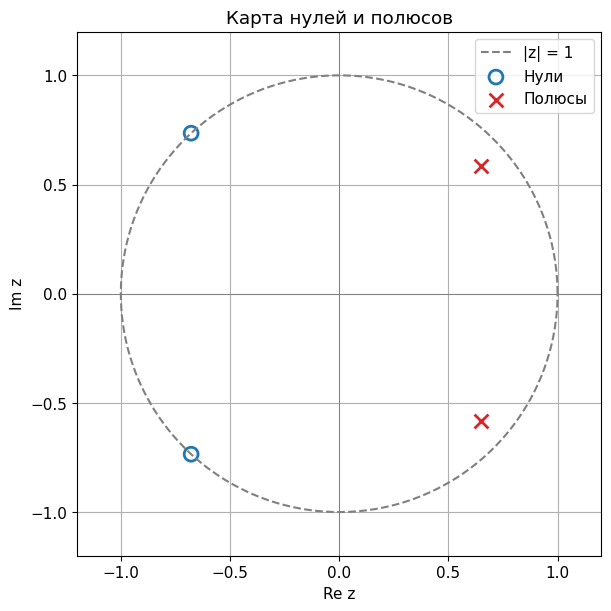

Модули полюсов: [0.87521426 0.87521426]
Система устойчива: True


In [6]:
circle_angle = np.linspace(0, 2 * np.pi, 500)
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
ax.plot(np.cos(circle_angle), np.sin(circle_angle), "--", color="gray", label="|z| = 1")
ax.scatter(zeros.real, zeros.imag, marker="o", s=100, facecolors="none",
           edgecolors="tab:blue", linewidths=2, label="Нули")
ax.scatter(poles.real, poles.imag, marker="x", s=100, color="tab:red",
           linewidths=2, label="Полюсы")
ax.axhline(0, color="gray", lw=0.7)
ax.axvline(0, color="gray", lw=0.7)
ax.set(xlabel="Re z", ylabel="Im z", title="Карта нулей и полюсов",
       xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
ax.grid()
ax.legend()
plt.show()
print("Модули полюсов:", np.abs(poles))
print("Система устойчива:", bool(np.all(np.abs(poles) < 1)))


Оба полюса находятся строго внутри единичной окружности: $|p_{1,2}|=\sqrt{0.766}\approx0.87521426<1$. Следовательно, причинное звено устойчиво. Нули лежат на единичной окружности. На карту нанесены те же корни, что вычислены в пункте 4; их значения дополнительно проверены функцией `tf2zpk`.


#### 6. АЧХ и ФЧХ в шкале нормированной частоты

На графиках используется неотрицательная половина основной полосы $0\leq\widehat\omega\leq\pi$, по горизонтальной оси отложено $\widehat\omega/\pi$. В точке нуля АЧХ фаза не определена, поэтому этот отсчёт на графике ФЧХ пропускается.


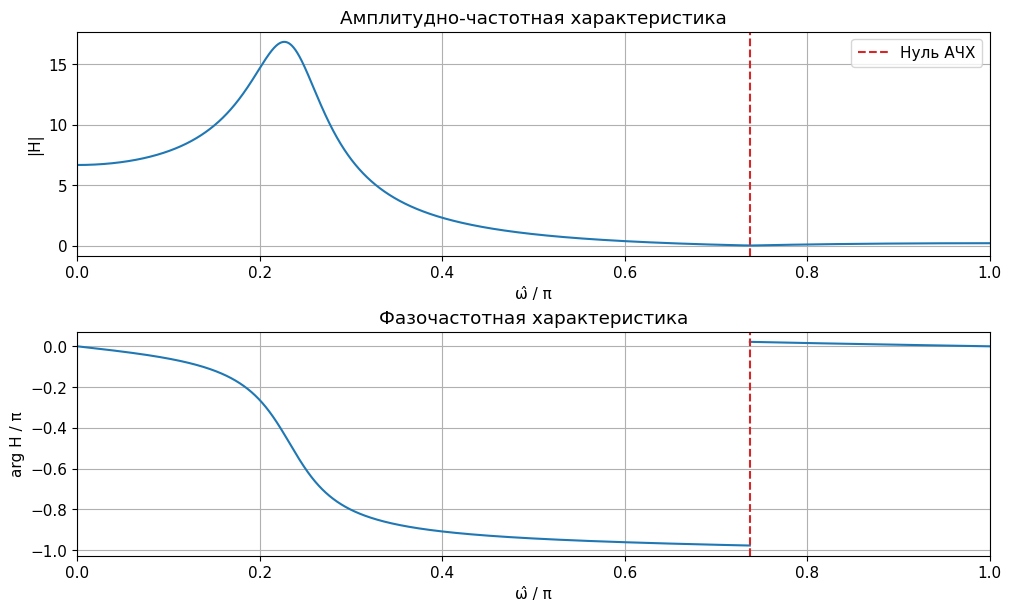

Частота нуля: omega/pi = 0.73715307
АЧХ в нуле: 5.028e-17
АЧХ на границах: H(0) = 6.66563040; H(pi) = 0.19306569
Максимум на сетке: 16.855999 при omega/pi = 0.226929


In [7]:
theta_zero = np.max(np.angle(zeros))
omega = np.unique(np.r_[np.linspace(0, np.pi, 16385), theta_zero])
_, H = signal.freqz(b, a, worN=omega)
magnitude = np.abs(H)
phase = np.angle(H)
phase[magnitude < 1e-12] = np.nan

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].plot(omega / np.pi, magnitude)
axes[0].set(ylabel="|H|", title="Амплитудно-частотная характеристика")
axes[1].plot(omega / np.pi, phase / np.pi)
axes[1].set(ylabel="arg H / π", title="Фазочастотная характеристика")
for ax in axes:
    ax.axvline(theta_zero / np.pi, ls="--", color="tab:red", label="Нуль АЧХ")
    ax.set(xlabel="ω̂ / π", xlim=(0, 1))
    ax.grid()
axes[0].legend()
plt.show()

_, H_edges = signal.freqz(b, a, worN=np.array([0.0, np.pi]))
_, H_zero = signal.freqz(b, a, worN=np.array([theta_zero]))
peak = np.argmax(magnitude)
print(f"Частота нуля: omega/pi = {theta_zero / np.pi:.8f}")
print(f"АЧХ в нуле: {abs(H_zero[0]):.3e}")
print(f"АЧХ на границах: H(0) = {abs(H_edges[0]):.8f}; H(pi) = {abs(H_edges[1]):.8f}")
print(f"Максимум на сетке: {magnitude[peak]:.6f} при omega/pi = {omega[peak] / np.pi:.6f}")


Полная основная полоса нормированных угловых частот — $[-\pi,\pi)$; для вещественной системы отрицательная половина определяется комплексным сопряжением положительной.

Полюсы с аргументами $\pm0.23279525\pi$ создают резонансное усиление поблизости: максимум АЧХ примерно $16.856$ при $\widehat\omega\approx0.2269\pi$. Максимум не обязан точно совпадать с аргументом полюса, поскольку на АЧХ влияют и остальные корни.

Для числителя на единичной окружности выполняется

$$0.92+1.24752e^{-j\widehat\omega}+0.92e^{-j2\widehat\omega}=e^{-j\widehat\omega}(1.24752+1.84\cos\widehat\omega).$$

Поэтому при $\widehat\omega_0=\arccos(-1.24752/1.84)\approx0.73715307\pi$ АЧХ равна нулю. В этой точке вещественный множитель меняет знак, и односторонние значения фазы отличаются на $\pi$. Фаза в самом нуле не определена.

На постоянной составляющей $|H(0)|\approx6.66563$, у частоты Найквиста $|H(\pi)|\approx0.19307$. Высокочастотные составляющие прямоугольного воздействия подавляются преимущественно сильнее низкочастотных, причём на частоте нуля подавление полное. Характеристика также имеет выраженный резонанс в нижней части полосы.


#### 7. АЧХ и ФЧХ в герцах

Частоты двух шкал связаны равенством $f=\widehat\omega f_{s,1}/(2\pi)$. При $f_{s,1}=21000$ Гц основная полоса равна $[-10500,10500)$ Гц, а на графиках представлена её половина $[0,10500]$ Гц.


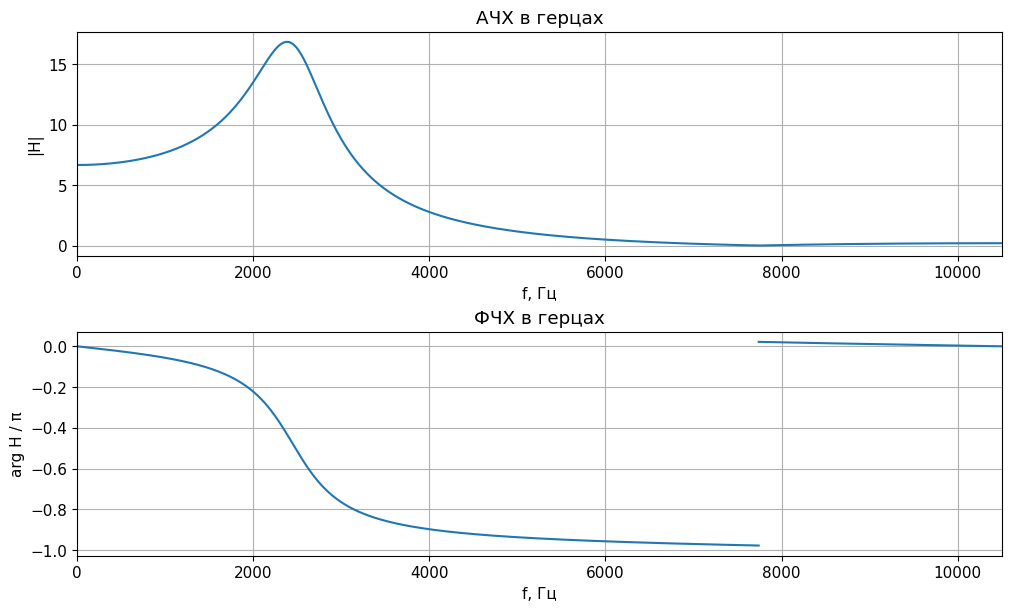

Частота нуля: 7740.107257 Гц


In [8]:
frequency = omega * fs1 / (2 * np.pi)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].plot(frequency, magnitude)
axes[0].set(ylabel="|H|", title="АЧХ в герцах")
axes[1].plot(frequency, phase / np.pi)
axes[1].set(ylabel="arg H / π", title="ФЧХ в герцах")
for ax in axes:
    ax.set(xlabel="f, Гц", xlim=(0, fs1 / 2))
    ax.grid()
plt.show()
print(f"Частота нуля: {theta_zero * fs1 / (2 * np.pi):.6f} Гц")


Значениям $\widehat\omega=0$ и $\widehat\omega=\pi$ соответствуют $f=0$ и $f=10500$ Гц. Нуль АЧХ находится при $f\approx7740.10726$ Гц. Переход к герцам меняет только масштаб частотной оси, значения АЧХ и ФЧХ сохраняются.


### Часть 2. Дискретное преобразование Фурье

#### 1. Исходная последовательность

По условию

$$x[n]=A_1\cos(2\pi f_1nT+\pi/4)+A_2\cos(2\pi f_2nT+\pi/8),\qquad 0\leq n<64.$$

Для варианта 21 это

$$x[n]=1.21\cos(\pi n/4+\pi/4)+2.42\cos(3\pi n/8+\pi/8).$$

Дискретное физическое время $t_n=nT$ измеряется в секундах, дискретное нормированное время $t_n/T=n$ — в номерах отсчётов. Заданный период $N=64$ соответствует интервалу $NT=0.016$ с. Он не является минимальным: гармоники имеют периоды 8 и 16 отсчётов, поэтому минимальный период суммы равен 16 отсчётам, или $0.004$ с. Блок из 64 отсчётов содержит четыре таких периода.


fs2 = 4000 Гц; T = 0.00025 с; NT = 0.016 с
A1 = 1.21; A2 = 2.42; f1 = 500.0 Гц; f2 = 750.0 Гц


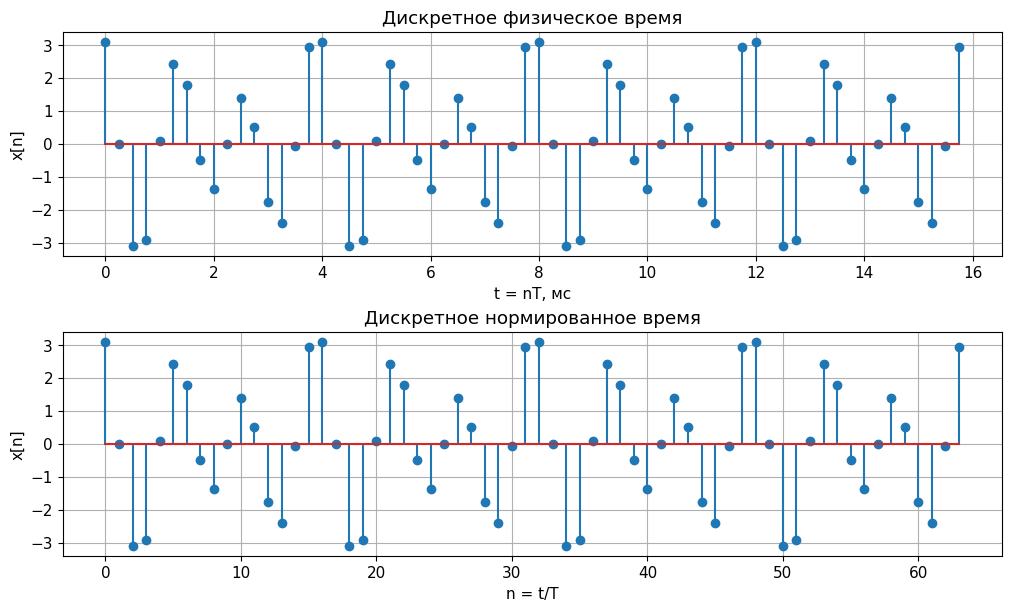

In [9]:
N = 64
fs2 = 2000 * (variant % 5 + 1)
T = 1 / fs2
A1 = 1 + 0.01 * variant
A2 = 2 * A1
f1 = fs2 / 8
f2 = 1.5 * f1
n2 = np.arange(N)
t_samples = n2 * T
x2 = (A1 * np.cos(2 * np.pi * f1 * t_samples + np.pi / 4)
      + A2 * np.cos(2 * np.pi * f2 * t_samples + np.pi / 8))
print(f"fs2 = {fs2} Гц; T = {T} с; NT = {N * T} с")
print(f"A1 = {A1}; A2 = {A2}; f1 = {f1} Гц; f2 = {f2} Гц")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(t_samples * 1000, x2)
axes[0].set(xlabel="t = nT, мс", ylabel="x[n]", title="Дискретное физическое время")
axes[1].stem(n2, x2)
axes[1].set(xlabel="n = t/T", ylabel="x[n]", title="Дискретное нормированное время")
for ax in axes:
    ax.grid()
plt.show()


#### 2. ДПФ и обратное преобразование


Максимальная ошибка ОДПФ: 1.332e-15
Максимальная мнимая часть: 2.555e-16


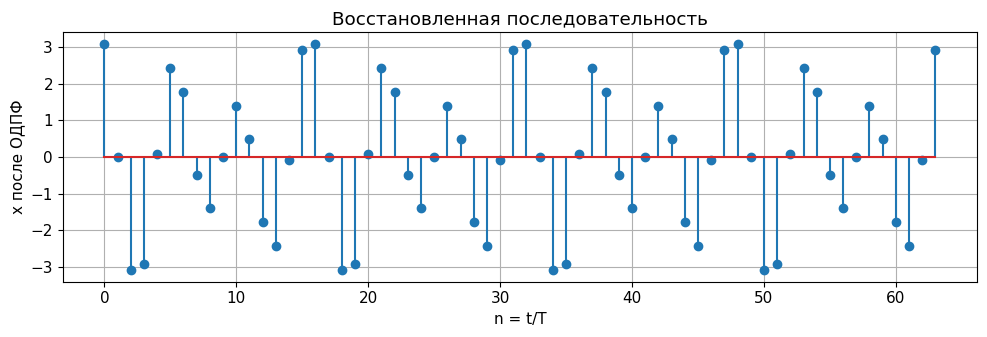

In [10]:
X = np.fft.fft(x2)
x_inverse = np.fft.ifft(X)
error_inverse = np.max(np.abs(x_inverse - x2))
assert error_inverse < 1e-12
print(f"Максимальная ошибка ОДПФ: {error_inverse:.3e}")
print(f"Максимальная мнимая часть: {np.max(np.abs(x_inverse.imag)):.3e}")

plt.figure()
plt.stem(n2, x_inverse.real)
plt.xlabel("n = t/T")
plt.ylabel("x после ОДПФ")
plt.title("Восстановленная последовательность")
plt.grid()
plt.tight_layout()
plt.show()


ОДПФ восстанавливает все исходные отсчёты с погрешностью округления машинных чисел. Мнимая часть результата близка к нулю, поскольку исходная последовательность вещественная.


#### 3. Амплитудный и фазовый спектры

Для периодической последовательности вычисляются коэффициенты $C[k]=X[k]/N$. Спектры изображаются в центрированном порядке $k=-32,\ldots,31$, то есть отрицательные частоты находятся слева от нуля. Используется нормированная угловая частота $\widehat\omega_k=2\pi k/N$ и абсолютная частота $f_k=kf_{s,2}/N$.


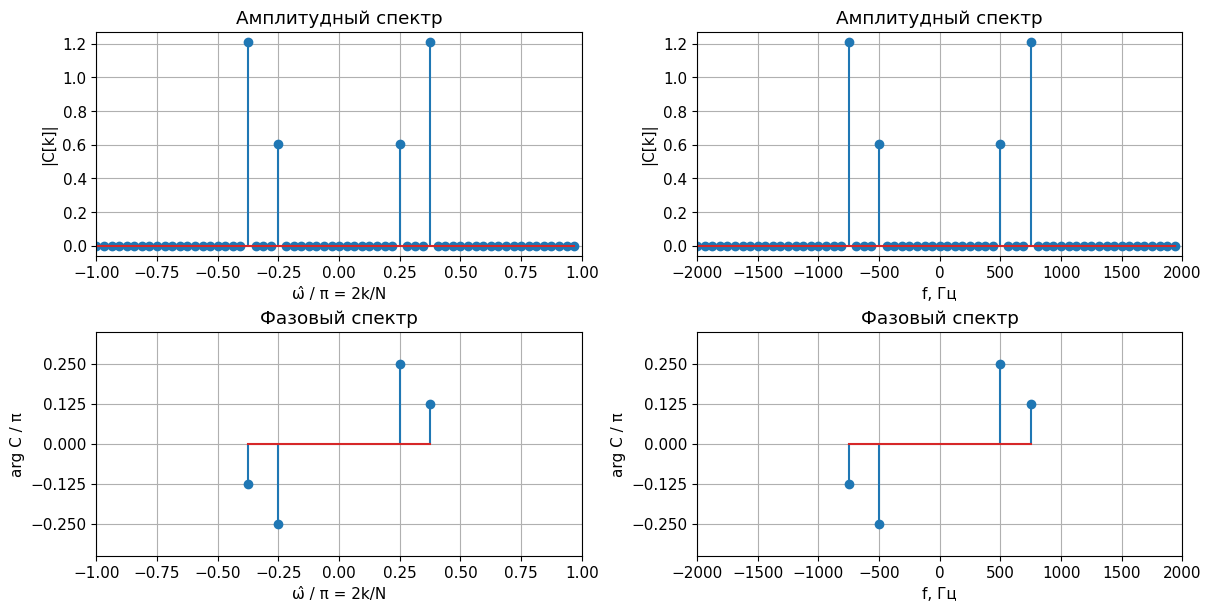

 k      f, Гц       |C[k]|      arg C / pi
-12     -750.00      1.21000     -0.12500
 -8     -500.00      0.60500     -0.25000
  8      500.00      0.60500     +0.25000
 12      750.00      1.21000     +0.12500


In [11]:
k_center = np.arange(-N // 2, N // 2)
nu_center = k_center / N
f_center = nu_center * fs2
C_center = np.fft.fftshift(X / N)
amplitude = np.abs(C_center)
active = amplitude > 1e-10 * np.max(amplitude)
phases = np.angle(C_center[active])

fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")
for col, (axis_values, axis_label) in enumerate([
    (2 * nu_center, "ω̂ / π = 2k/N"), (f_center, "f, Гц")
]):
    axes[0, col].stem(axis_values, amplitude)
    axes[0, col].set(xlabel=axis_label, ylabel="|C[k]|", title="Амплитудный спектр")
    axes[1, col].stem(axis_values[active], phases / np.pi)
    axes[1, col].set(xlabel=axis_label, ylabel="arg C / π", title="Фазовый спектр",
                     ylim=(-0.35, 0.35))
    axes[1, col].set_yticks([-0.25, -0.125, 0, 0.125, 0.25])
    for row in range(2):
        axes[row, col].set_xlim(axis_values[0], -axis_values[0])
for ax in axes.flat:
    ax.grid()
plt.show()

print(" k      f, Гц       |C[k]|      arg C / pi")
for k, f, c in zip(k_center[active], f_center[active], C_center[active]):
    print(f"{k:3d}    {f:8.2f}    {abs(c):9.5f}     {np.angle(c) / np.pi:+.5f}")


Связь шкал: $\nu_k=k/N$, $\widehat\omega_k=2\pi\nu_k$, $f_k=\nu_k f_{s,2}$. Частотный шаг равен $\Delta f=f_{s,2}/N=62.5$ Гц. Получены четыре ненулевые линии:

| $k$ в центрированной шкале | $\nu=k/N$ | $f$, Гц | $|C[k]|$ | $\arg C[k]$ |
|---|---|---|---|---|
| $-12$ | $-3/16$ | $-750$ | $1.21$ | $-\pi/8$ |
| $-8$ | $-1/8$ | $-500$ | $0.605$ | $-\pi/4$ |
| $8$ | $1/8$ | $500$ | $0.605$ | $\pi/4$ |
| $12$ | $3/16$ | $750$ | $1.21$ | $\pi/8$ |

Спектр состоит из пар сопряжённых коэффициентов, поскольку сигнал вещественный. Амплитудный спектр чётный, фазовый — нечётный на ненулевых линиях. Гармоники точно попадают в узлы $k=8$ и $k=12$, поэтому спектрального растекания нет. В обычной нумерации ДПФ отрицательным частотам соответствуют индексы $52$ и $56$. Фазы коэффициентов с практически нулевой амплитудой не изображаются: в этих точках фаза не определена.


#### 4. ДПФ конечной последовательности

Тот же блок из $N=64$ отсчётов рассматривается как конечная последовательность, равная нулю вне $0\leq n<N$. Для независимой проверки ДПФ вычисляется непосредственно по определению. Сравниваются модуль ДПФ конечной последовательности и амплитуды ряда Фурье её периодического продолжения.


Ошибка прямого вычисления ДПФ относительно FFT: 5.373e-13
Ненулевые значения |X|: [77.44 38.72 38.72 77.44]


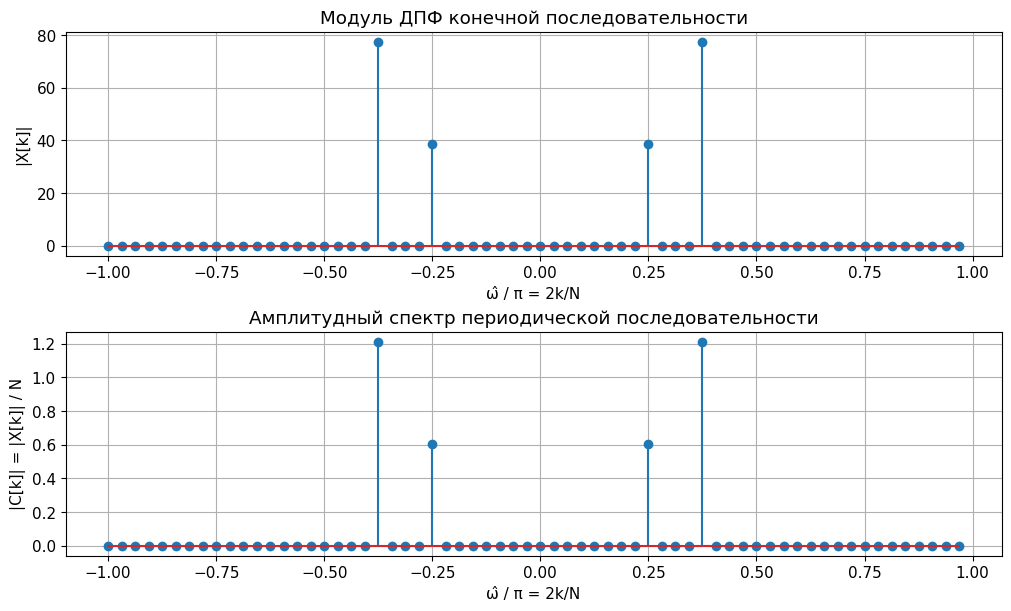

In [12]:
k_dft = np.arange(N)
dft_matrix = np.exp(-2j * np.pi * np.outer(k_dft, n2) / N)
X_finite = dft_matrix @ x2
error_dft = np.max(np.abs(X_finite - X))
assert np.allclose(X_finite, X, atol=1e-10, rtol=0)
print(f"Ошибка прямого вычисления ДПФ относительно FFT: {error_dft:.3e}")
print("Ненулевые значения |X|:", np.abs(np.fft.fftshift(X_finite))[active])

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(2 * nu_center, np.abs(np.fft.fftshift(X_finite)))
axes[0].set(ylabel="|X[k]|", title="Модуль ДПФ конечной последовательности")
axes[1].stem(2 * nu_center, amplitude)
axes[1].set(ylabel="|C[k]| = |X[k]| / N", title="Амплитудный спектр периодической последовательности")
for ax in axes:
    ax.set(xlabel="ω̂ / π = 2k/N")
    ax.grid()
plt.show()


В узлах ДПФ выполняется $|X[k]|=N|C[k]|$. Поэтому положение линий совпадает, а высоты различаются в 64 раза: $38.72$ вместо $0.605$ и $77.44$ вместо $1.21$. Конечный блок и один период имеют одинаковый массив ДПФ, но различную интерпретацию. У конечной последовательности непрерывное по частоте преобразование Фурье, отсчёты которого даёт ДПФ; у периодического продолжения спектр линейчатый.


#### 5. Восстановление аналогового сигнала

Используется именно сумма из условия:

$$x_r(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a[k]\exp\left(j\frac{2\pi kt}{NT}\right),$$

$$X_a[k]=\begin{cases}X[N+k],&-N/2\leq k\leq-1,\\X[k],&0\leq k\leq N/2-1.\end{cases}$$

Время задаётся на $[0,(N-1)T]$ с шагом $\Delta t=0.25T=0.0000625$ с, включая обе границы. Коэффициенты аналогового ряда Фурье равны $c_k=X_a[k]/N$; модуль этих коэффициентов задаёт высоту спектральных линий.


Число точек: 253; шаг: 0.00006250 с
Конец интервала: 0.01575000 с = (N - 1)T
Ошибка восстановления на плотной сетке: 3.398e-14
Ошибка в исходных отсчётах: 2.387e-14
Максимальная мнимая часть: 1.196e-15


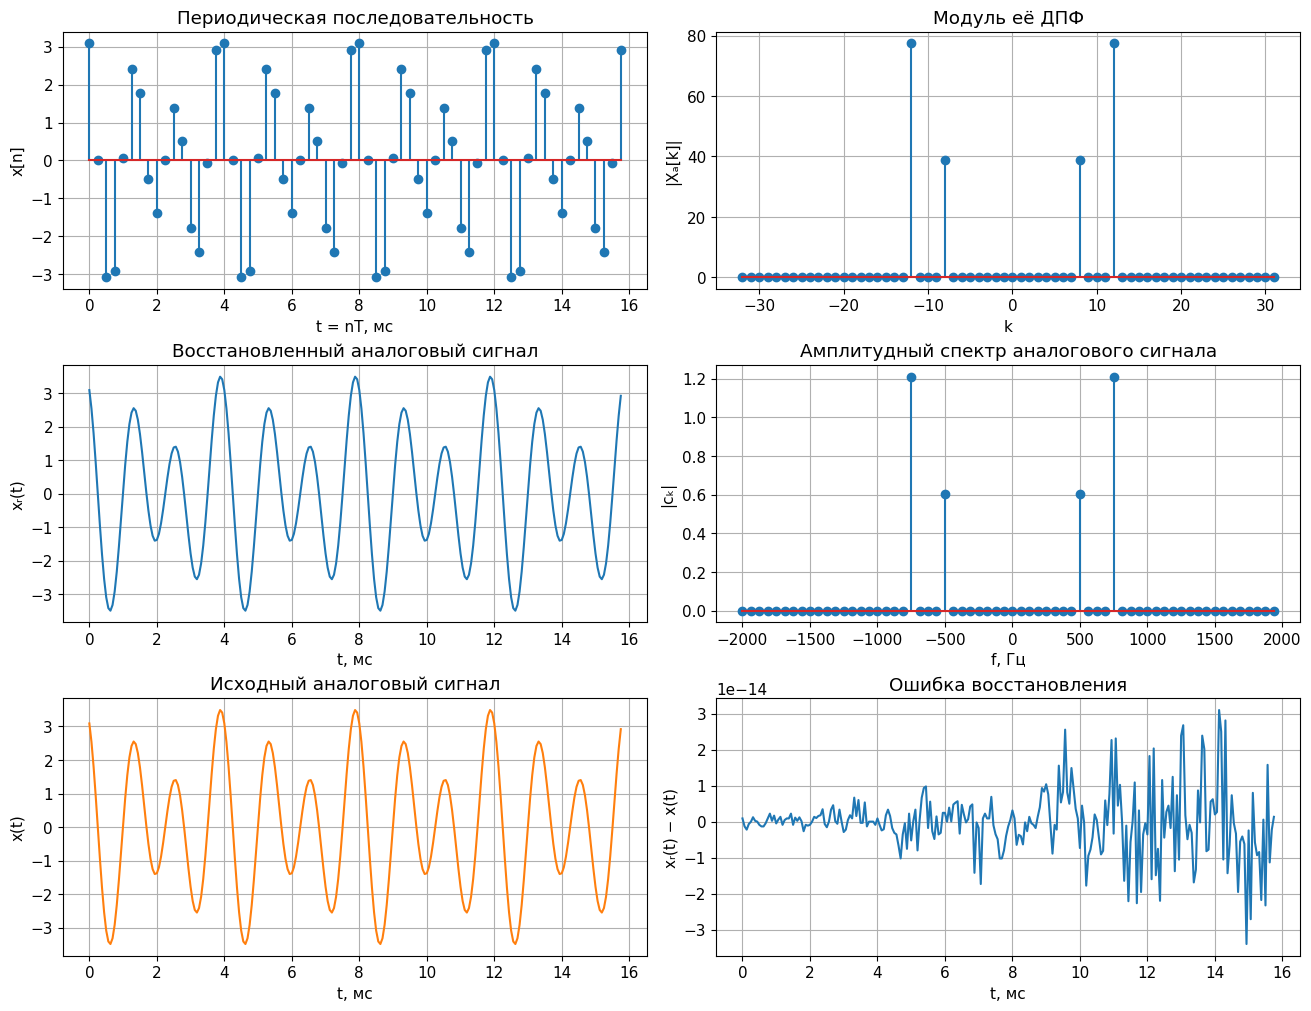

In [13]:
X_a = np.empty(N, dtype=complex)
for index, k in enumerate(k_center):
    X_a[index] = X[N + k] if k < 0 else X[k]
assert np.allclose(X_a, np.fft.fftshift(X), atol=1e-12, rtol=0)

t_dense = np.arange(4 * (N - 1) + 1) * (T / 4)
exponent = np.exp(2j * np.pi * np.outer(t_dense, k_center) / (N * T))
x_reconstructed = exponent @ X_a / N
x_original = (A1 * np.cos(2 * np.pi * f1 * t_dense + np.pi / 4)
              + A2 * np.cos(2 * np.pi * f2 * t_dense + np.pi / 8))
analog_amplitude = np.abs(X_a / N)
error_reconstruction = np.max(np.abs(x_reconstructed - x_original))
error_samples = np.max(np.abs(x_reconstructed[::4] - x2))
assert error_reconstruction < 1e-12
assert error_samples < 1e-12
print(f"Число точек: {len(t_dense)}; шаг: {T / 4:.8f} с")
print(f"Конец интервала: {t_dense[-1]:.8f} с = (N - 1)T")
print(f"Ошибка восстановления на плотной сетке: {error_reconstruction:.3e}")
print(f"Ошибка в исходных отсчётах: {error_samples:.3e}")
print(f"Максимальная мнимая часть: {np.max(np.abs(x_reconstructed.imag)):.3e}")

fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout="constrained")
axes[0, 0].stem(t_samples * 1000, x2)
axes[0, 0].set(xlabel="t = nT, мс", ylabel="x[n]", title="Периодическая последовательность")
axes[0, 1].stem(k_center, np.abs(X_a))
axes[0, 1].set(xlabel="k", ylabel="|Xₐ[k]|", title="Модуль её ДПФ")
axes[1, 0].plot(t_dense * 1000, x_reconstructed.real)
axes[1, 0].set(xlabel="t, мс", ylabel="xᵣ(t)", title="Восстановленный аналоговый сигнал")
axes[1, 1].stem(f_center, analog_amplitude)
axes[1, 1].set(xlabel="f, Гц", ylabel="|cₖ|", title="Амплитудный спектр аналогового сигнала")
axes[2, 0].plot(t_dense * 1000, x_original, color="tab:orange")
axes[2, 0].set(xlabel="t, мс", ylabel="x(t)", title="Исходный аналоговый сигнал")
axes[2, 1].plot(t_dense * 1000, x_reconstructed.real - x_original)
axes[2, 1].set(xlabel="t, мс", ylabel="xᵣ(t) − x(t)", title="Ошибка восстановления")
for ax in axes.flat:
    ax.grid()
plt.show()


#### 6. Интерпретация восстановления

Спектр восстановленного аналогового сигнала имеет вид $\sum_k c_k\delta(f-k/(NT))$, где $c_k=X_a[k]/N$. Таким образом, модуль ДПФ необходимо разделить на $N=64$ и перенести индексы старшей половины в отрицательные частоты. Линии находятся при $\pm500$ и $\pm750$ Гц; их высоты равны $0.605$ и $1.21$. Амплитуды двух косинусов в одностороннем представлении равны удвоенным высотам соответствующих положительных линий, то есть $1.21$ и $2.42$.

Графики восстановленного и исходного сигналов визуально совпадают, что подтверждается численной ошибкой. Обе гармоники лежат ниже частоты Найквиста $f_{s,2}/2=2000$ Гц, а блок содержит целое число их периодов. Поэтому отсутствуют наложение спектров и спектральное растекание. В сумме восстановления присутствуют все четыре ненулевые линии с правильными фазами. Совпадение проверено на всей сетке с шагом $T/4$, а также в исходных точках $t=nT$.


#### 7. Равенство Парсеваля

Для конечного блока проверяется

$$E_t=\sum_{n=0}^{N-1}|x[n]|^2,\qquad E_f=\frac1N\sum_{k=0}^{N-1}|X[k]|^2.$$

Поскольку гармоники ортогональны на выбранном интервале,

$$E_t=\frac N2(A_1^2+A_2^2)=234.256,\qquad P=\frac{E_t}{N}=3.66025.$$


In [14]:
energy_time = np.sum(np.abs(x2)**2)
energy_frequency = np.sum(np.abs(X)**2) / N
energy_expected = N * (A1**2 + A2**2) / 2
power_fourier = np.sum(np.abs(X / N)**2)
assert np.isclose(energy_time, energy_frequency, atol=1e-10, rtol=0)
assert np.isclose(energy_time, energy_expected, atol=1e-10, rtol=0)
assert np.isclose(energy_time / N, power_fourier, atol=1e-12, rtol=0)
print(f"Энергия во временной области: {energy_time:.12f}")
print(f"Энергия в частотной области: {energy_frequency:.12f}")
print(f"Энергия по амплитудам гармоник: {energy_expected:.12f}")
print(f"Абсолютное расхождение: {abs(energy_time - energy_frequency):.3e}")
print(f"Средняя мощность: {power_fourier:.8f}")


Энергия во временной области: 234.256000000000
Энергия в частотной области: 234.256000000000
Энергия по амплитудам гармоник: 234.256000000000
Абсолютное расхождение: 5.684e-14
Средняя мощность: 3.66025000


Равенство выполнено с точностью машинных вычислений. ДПФ сохраняет энергию при учёте множителя $1/N$ выбранной нормировки. Для периодического сигнала значение $234.256$ — энергия блока из 64 отсчётов, а не всей бесконечной последовательности; её средняя мощность равна $3.66025$ и также равна $\sum_k|C[k]|^2$.


## Выводы

Для варианта 21 реализовано рекурсивное звено второго порядка. Аналитическая импульсная характеристика совпала с численным расчётом. Она бесконечна и затухает, поскольку модули обоих полюсов равны примерно $0.87521426<1$. Вычисленный фрагмент из 21 отсчёта является усечением этой характеристики.

Реакции по свёртке и разностному уравнению совпали на первых 21 отсчёте. Дальнейшее расхождение объясняется усечением ИХ; его максимум на интервале длины 31 составил примерно $0.42225839$. Разграничены длина массива воздействия (31), длительность ненулевого импульса (16), длина полной свёртки массивов (51) и её ненулевая часть (36).

Карта нулей и полюсов согласуется с частотными характеристиками. Нули на единичной окружности дают полное подавление на частоте примерно $7740.10726$ Гц и изменение фазы на $\pi$. В целом высокие частоты подавляются сильнее низких; в нижней части полосы присутствует резонанс.

Для суммы гармоник 500 и 750 Гц получены четыре спектральные линии с ожидаемыми амплитудами и фазами. Подтверждена связь между модулем ДПФ конечного блока и амплитудами периодического сигнала через множитель $N$. ОДПФ и явная сумма комплексных гармоник восстановили соответственно отсчёты и аналоговый сигнал с погрешностью округления. Равенство Парсеваля подтвердило согласованность нормировки спектра и энергетических расчётов.
